## 1. Load and verify the tour-level inputs

We will compare alternative clustering algorithms using the same five standardized features and the same candidate tours used in the existing analysis. Vehicle and tour IDs are kept for alignment, not used as model features. Quality flags and existing cluster labels are reserved for later profiling and comparison.

In [1]:
from pathlib import Path
import json

import pandas as pd

DATA_DIR = Path(
    "/Users/divyshah/Desktop/dt-cargo-vehicle-telemetry--main/data"
)
MODEL_DIR = DATA_DIR / "processed" / "tour_level_pca"

FEATURES_PATH = MODEL_DIR / "tour_level_pca_standardized_features.csv"
ASSIGNMENTS_PATH = MODEL_DIR / "tour_level_pca_kmeans_k4_assignments.csv"
METADATA_PATH = MODEL_DIR / "tour_level_pca_metadata.json"

for path in [FEATURES_PATH, ASSIGNMENTS_PATH, METADATA_PATH]:
    if not path.exists():
        raise FileNotFoundError(f"Required file not found: {path}")

features_df = pd.read_csv(FEATURES_PATH)
assignments_df = pd.read_csv(ASSIGNMENTS_PATH)

with METADATA_PATH.open(encoding="utf-8") as file:
    pca_metadata = json.load(file)

ID_COLS = ["vehicle_id", "tour_id"]
FEATURE_COLS = [
    "scaled_total_distance_km",
    "scaled_recorded_track_hours",
    "scaled_elapsed_span_hours",
    "scaled_distance_based_avg_speed_kmh",
    "scaled_track_count",
]

missing_features = [col for col in FEATURE_COLS if col not in features_df.columns]
if missing_features:
    raise ValueError(f"Missing model features: {missing_features}")

if not features_df[ID_COLS].equals(assignments_df[ID_COLS]):
    raise ValueError("Feature rows and saved assignment rows are not aligned.")

X = features_df[FEATURE_COLS].copy()

print(f"Tour rows: {len(features_df):,}")
print(f"Model feature matrix: {X.shape}")
print("Feature and assignment IDs aligned: True")
print(
    "PCA variance retained: "
    f"{pca_metadata['cumulative_variance_retained_pct']:.3f}%"
)
print("\nSaved K-Means cluster counts:")
print(assignments_df["pca_cluster"].value_counts().sort_index().to_string())

Tour rows: 13,413
Model feature matrix: (13413, 5)
Feature and assignment IDs aligned: True
PCA variance retained: 91.081%

Saved K-Means cluster counts:
pca_cluster
0    5390
1    2011
2    1100
3    4912


## 2. Validate the feature matrix

Before fitting alternative models, verify that the feature matrix contains finite numeric values, each `(vehicle_id, tour_id)` key is unique, and the features are standardized. This helps ensure model comparisons use a consistent input.

In [2]:
import numpy as np

X_values = X.to_numpy(dtype=float)

missing_cells = int(X.isna().sum().sum())
non_finite_cells = int((~np.isfinite(X_values)).sum())
duplicate_tour_keys = int(features_df.duplicated(ID_COLS).sum())

feature_summary = pd.DataFrame({
    "mean": X.mean(),
    "std": X.std(ddof=0),
    "min": X.min(),
    "max": X.max(),
}).round(3)

print(f"Missing cells: {missing_cells}")
print(f"Non-finite cells: {non_finite_cells}")
print(f"Duplicate tour keys: {duplicate_tour_keys}")
print("\nFeature summary:")
display(feature_summary)

assert missing_cells == 0, "Handle missing values before modeling."
assert non_finite_cells == 0, "Handle non-finite values before modeling."
assert duplicate_tour_keys == 0, "Resolve duplicate tour keys before modeling."

Missing cells: 0
Non-finite cells: 0
Duplicate tour keys: 0

Feature summary:


,mean,std,min,max
scaled_total_distance_km,0.0,1.0,-1.370,2.695
scaled_recorded_track_hours,0.0,1.0,-1.214,5.111
scaled_elapsed_span_hours,0.0,1.0,-1.371,4.832
scaled_distance_based_avg_speed_kmh,-0.0,1.0,-1.022,26.559
scaled_track_count,0.0,1.0,-1.263,6.690


## 3. Inspect extreme speed values

Standardization puts features on comparable scales, but it does not remove the influence of extreme observations. Review the tours with the highest standardized average-speed values alongside the existing speed and quality flags. Keep all tours for now; this is an audit, not a filtering step.

In [3]:
SPEED_Z_COL = "scaled_distance_based_avg_speed_kmh"
RAW_SPEED_COL = "distance_based_avg_speed_kmh"
SPEED_FLAG_COL = "high_distance_based_speed"
REVIEW_FLAG_COL = "requires_quality_review"

required_audit_cols = [
    RAW_SPEED_COL,
    SPEED_FLAG_COL,
    REVIEW_FLAG_COL,
]
missing_audit_cols = [
    col for col in required_audit_cols
    if col not in assignments_df.columns
]
if missing_audit_cols:
    raise ValueError(f"Missing audit columns: {missing_audit_cols}")

speed_audit = pd.DataFrame({
    "vehicle_id": assignments_df["vehicle_id"],
    "tour_id": assignments_df["tour_id"],
    "raw_speed_kmh": assignments_df[RAW_SPEED_COL],
    "speed_z_score": X[SPEED_Z_COL],
    "high_speed_flag": assignments_df[SPEED_FLAG_COL],
    "quality_review_flag": assignments_df[REVIEW_FLAG_COL],
})

print(
    "Tours with speed |z-score| > 3:",
    int((speed_audit["speed_z_score"].abs() > 3).sum()),
)
print(
    "Tours flagged for high distance-based speed:",
    int(speed_audit["high_speed_flag"].fillna(False).sum()),
)

display(
    speed_audit
    .sort_values("speed_z_score", ascending=False)
    .head(10)
    .round(3)
)

Tours with speed |z-score| > 3: 28
Tours flagged for high distance-based speed: 16


,vehicle_id,tour_id,raw_speed_kmh,speed_z_score,high_speed_flag,quality_review_flag
10748,59,10761,653.904,26.559,True,True
8945,54,8954,563.956,22.765,True,True
3806,22,3813,334.299,13.078,True,True
270,2,270,305.078,11.846,True,True
6546,33,6557,225.445,8.487,True,True
3981,22,3988,194.974,7.202,True,True
2520,15,2526,191.359,7.049,True,True
9653,55,9666,171.887,6.228,True,True
8784,54,8793,153.545,5.454,True,True
11545,61,11559,152.672,5.417,True,True


## 4. Reproduce the K-Means baseline

Fit K-Means to the five standardized features. This gives us a reference for comparing alternative algorithms on the same tours and inputs. We also compare its labels with the saved PCA-based K-Means labels; cluster numbers themselves are arbitrary.

In [4]:
from sklearn.cluster import KMeans
from sklearn.metrics import (
    adjusted_rand_score,
    calinski_harabasz_score,
    davies_bouldin_score,
    silhouette_score,
)

RANDOM_STATE = 42
N_INIT = 20
K_SELECTED = 4
SILHOUETTE_SAMPLE_SIZE = min(3000, len(X))

X_array = X.to_numpy(dtype=float)

rng = np.random.default_rng(RANDOM_STATE)
sample_positions = np.sort(
    rng.choice(
        len(X_array),
        size=SILHOUETTE_SAMPLE_SIZE,
        replace=False,
    )
)

kmeans_reference = KMeans(
    n_clusters=K_SELECTED,
    random_state=RANDOM_STATE,
    n_init=N_INIT,
)
kmeans_labels = kmeans_reference.fit_predict(X_array)

baseline_silhouette = silhouette_score(
    X_array[sample_positions],
    kmeans_labels[sample_positions],
)

baseline_metrics = pd.DataFrame([{
    "model": "K-Means",
    "k": K_SELECTED,
    "sampled_silhouette": baseline_silhouette,
    "calinski_harabasz": calinski_harabasz_score(X_array, kmeans_labels),
    "davies_bouldin": davies_bouldin_score(X_array, kmeans_labels),
    "inertia": kmeans_reference.inertia_,
    "ARI_vs_saved_PCA_KMeans": adjusted_rand_score(
        kmeans_labels,
        assignments_df["pca_cluster"].to_numpy(),
    ),
}])

print("K-Means baseline metrics:")
display(baseline_metrics.round(4))

print("K-Means cluster sizes:")
display(
    pd.Series(kmeans_labels, name="tour_count")
    .value_counts()
    .sort_index()
    .to_frame()
)

K-Means baseline metrics:


,model,k,sampled_silhouette,calinski_harabasz,davies_bouldin,inertia,ARI_vs_saved_PCA_KMeans
0,K-Means,4,0.4525,10270.2115,0.8545,20336.5521,0.944


K-Means cluster sizes:


,count
tour_count,
0,2033
1,5478
2,1157
3,4745


## 5. Gaussian Mixture Model

Fit a four-component Gaussian Mixture Model to the same five standardized features. Compare its sampled silhouette and cluster profiles with K-Means, and inspect posterior assignment confidence. Keep all tours, including flagged outliers.

In [5]:
from sklearn.mixture import GaussianMixture

gmm = GaussianMixture(
    n_components=K_SELECTED,
    covariance_type="full",
    random_state=RANDOM_STATE,
    n_init=10,
    reg_covar=1e-6,
)

gmm_labels = gmm.fit_predict(X_array)
gmm_probabilities = gmm.predict_proba(X_array)
gmm_cluster_sizes = (
    pd.Series(gmm_labels, name="tour_count")
    .value_counts()
    .sort_index()
)

max_posterior = gmm_probabilities.max(axis=1)

gmm_row = {
    "model": "Gaussian Mixture",
    "k": len(gmm_cluster_sizes),
    "sampled_silhouette": silhouette_score(
        X_array[sample_positions],
        gmm_labels[sample_positions],
    ),
    "calinski_harabasz": calinski_harabasz_score(X_array, gmm_labels),
    "davies_bouldin": davies_bouldin_score(X_array, gmm_labels),
    "ARI_vs_KMeans": adjusted_rand_score(kmeans_labels, gmm_labels),
    "mean_max_posterior": max_posterior.mean(),
    "low_confidence_pct": (max_posterior < 0.70).mean() * 100,
    "AIC": gmm.aic(X_array),
    "BIC": gmm.bic(X_array),
    "converged": gmm.converged_,
    "iterations": gmm.n_iter_,
}

kmeans_row = {
    "model": "K-Means",
    "k": K_SELECTED,
    "sampled_silhouette": baseline_metrics.loc[0, "sampled_silhouette"],
    "calinski_harabasz": baseline_metrics.loc[0, "calinski_harabasz"],
    "davies_bouldin": baseline_metrics.loc[0, "davies_bouldin"],
    "ARI_vs_KMeans": 1.0,
    "mean_max_posterior": np.nan,
    "low_confidence_pct": np.nan,
    "AIC": np.nan,
    "BIC": np.nan,
    "converged": np.nan,
    "iterations": np.nan,
}

model_comparison = pd.DataFrame([kmeans_row, gmm_row])

print("Model comparison so far:")
display(model_comparison.round(4))

print("GMM cluster sizes:")
display(gmm_cluster_sizes.to_frame())

print(f"GMM converged: {gmm.converged_} ({gmm.n_iter_} iterations)")

Model comparison so far:


,model,k,sampled_silhouette,calinski_harabasz,davies_bouldin,ARI_vs_KMeans,mean_max_posterior,low_confidence_pct,AIC,BIC,converged,iterations
0,K-Means,4,0.4525,10270.2115,0.8545,1.0000,NaN,NaN,NaN,NaN,NaN,NaN
1,Gaussian Mixture,4,0.3035,5068.2397,1.6369,0.5933,0.9614,3.9812,56843.9698,57466.8001,True,17.0


GMM cluster sizes:


,count
tour_count,
0,3372
1,2488
2,2393
3,5160


GMM converged: True (17 iterations)


## 6. BIRCH clustering

BIRCH builds a compact tree of subclusters and then forms four final clusters. Fit it on the same five standardized features. We’ll start with a threshold of 0.5 and treat that setting as a comparison point, not a final tuning choice.

In [6]:
from sklearn.cluster import Birch

birch = Birch(
    threshold=0.5,
    branching_factor=50,
    n_clusters=K_SELECTED,
)

birch_labels = birch.fit_predict(X_array)

birch_cluster_sizes = (
    pd.Series(birch_labels, name="tour_count")
    .value_counts()
    .sort_index()
)

birch_row = {
    "model": "BIRCH",
    "k": len(birch_cluster_sizes),
    "sampled_silhouette": silhouette_score(
        X_array[sample_positions],
        birch_labels[sample_positions],
    ),
    "calinski_harabasz": calinski_harabasz_score(X_array, birch_labels),
    "davies_bouldin": davies_bouldin_score(X_array, birch_labels),
    "ARI_vs_KMeans": adjusted_rand_score(kmeans_labels, birch_labels),
    "mean_max_posterior": np.nan,
    "low_confidence_pct": np.nan,
    "AIC": np.nan,
    "BIC": np.nan,
    "converged": np.nan,
    "iterations": np.nan,
}

model_comparison = pd.concat(
    [model_comparison, pd.DataFrame([birch_row])],
    ignore_index=True,
)

print("Model comparison so far:")
display(model_comparison.round(4))

print(f"BIRCH subclusters before final grouping: {len(birch.subcluster_centers_)}")
print("BIRCH cluster sizes:")
display(birch_cluster_sizes.to_frame())

Model comparison so far:


,model,k,sampled_silhouette,calinski_harabasz,davies_bouldin,ARI_vs_KMeans,mean_max_posterior,low_confidence_pct,AIC,BIC,converged,iterations
0,K-Means,4,0.4525,10270.2115,0.8545,1.0000,NaN,NaN,NaN,NaN,NaN,NaN
1,Gaussian Mixture,4,0.3035,5068.2397,1.6369,0.5933,0.9614,3.9812,56843.9698,57466.8001,True,17.0
2,BIRCH,4,0.4514,1263.5304,0.7150,0.0879,NaN,NaN,NaN,NaN,NaN,NaN


BIRCH subclusters before final grouping: 362
BIRCH cluster sizes:


,count
tour_count,
0,12556
1,22
2,833
3,2


## 7. Choose a DBSCAN neighborhood radius

DBSCAN groups tours by local density and can mark tours that do not fit a dense group as noise. Its result depends strongly on the neighborhood radius (`eps`). We’ll inspect the distance to each tour’s 10th nearest neighbor to guide the choice of `eps`; this step does not fit DBSCAN yet.

K-distance quantiles:


,distance
quantile,
0.50,0.179
0.75,0.272
0.90,0.435
0.95,0.575
0.99,1.005


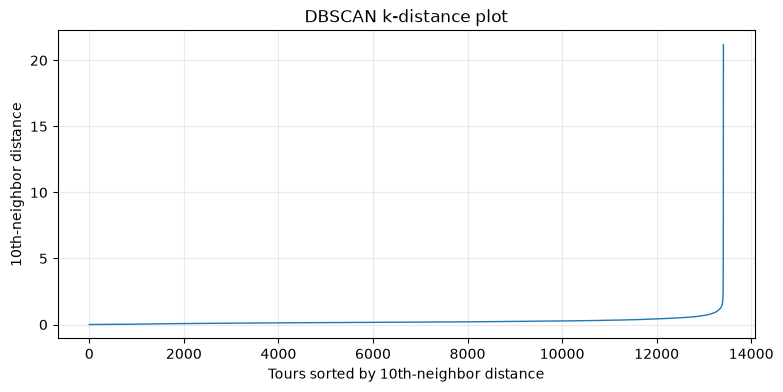

In [7]:
from sklearn.neighbors import NearestNeighbors
import matplotlib.pyplot as plt

MIN_SAMPLES_DBSCAN = 10

neighbors = NearestNeighbors(
    n_neighbors=MIN_SAMPLES_DBSCAN,
    metric="euclidean",
    n_jobs=-1,
)
neighbor_distances, _ = neighbors.fit(X_array).kneighbors(X_array)

k_distances = np.sort(neighbor_distances[:, -1])

print("K-distance quantiles:")
display(
    pd.Series(k_distances, name="distance")
    .quantile([0.50, 0.75, 0.90, 0.95, 0.99])
    .rename_axis("quantile")
    .to_frame()
    .round(3)
)

plt.figure(figsize=(9, 4))
plt.plot(k_distances, linewidth=1)
plt.xlabel("Tours sorted by 10th-neighbor distance")
plt.ylabel("10th-neighbor distance")
plt.title("DBSCAN k-distance plot")
plt.grid(alpha=0.25)
plt.show()

## 8. Run a small DBSCAN radius sweep

Test three `eps` values guided by the k-distance quantiles. For each run, report the number and sizes of non-noise clusters, the percentage marked as noise, and internal metrics on non-noise tours. This is a parameter comparison, not a final model selection.

In [8]:
from sklearn.cluster import DBSCAN

DBSCAN_EPS_VALUES = [0.30, 0.45, 0.60]
DBSCAN_MIN_SAMPLES = 10

dbscan_labels_by_eps = {}
dbscan_rows = []

for eps in DBSCAN_EPS_VALUES:
    model = DBSCAN(
        eps=eps,
        min_samples=DBSCAN_MIN_SAMPLES,
        metric="euclidean",
        n_jobs=-1,
    )
    labels = model.fit_predict(X_array)
    dbscan_labels_by_eps[eps] = labels

    non_noise_mask = labels != -1
    non_noise_labels = labels[non_noise_mask]
    cluster_sizes = pd.Series(non_noise_labels).value_counts()

    n_clusters = int(cluster_sizes.size)
    silhouette_value = np.nan
    ch_value = np.nan
    db_value = np.nan

    if n_clusters >= 2:
        sample_positions_non_noise = sample_positions[
            labels[sample_positions] != -1
        ]
        sample_labels_non_noise = labels[sample_positions_non_noise]
        sample_cluster_sizes = np.unique(
            sample_labels_non_noise,
            return_counts=True,
        )[1]

        if (
            len(np.unique(sample_labels_non_noise)) >= 2
            and sample_cluster_sizes.min() >= 2
        ):
            silhouette_value = silhouette_score(
                X_array[sample_positions_non_noise],
                sample_labels_non_noise,
            )

        X_non_noise = X_array[non_noise_mask]
        ch_value = calinski_harabasz_score(X_non_noise, non_noise_labels)
        db_value = davies_bouldin_score(X_non_noise, non_noise_labels)

    dbscan_rows.append({
        "eps": eps,
        "min_samples": DBSCAN_MIN_SAMPLES,
        "n_clusters": n_clusters,
        "noise_tours": int((~non_noise_mask).sum()),
        "noise_pct": (~non_noise_mask).mean() * 100,
        "smallest_cluster": (
            int(cluster_sizes.min()) if n_clusters else np.nan
        ),
        "largest_cluster": (
            int(cluster_sizes.max()) if n_clusters else np.nan
        ),
        "sampled_silhouette_non_noise": silhouette_value,
        "calinski_harabasz_non_noise": ch_value,
        "davies_bouldin_non_noise": db_value,
        "ARI_vs_KMeans": adjusted_rand_score(kmeans_labels, labels),
    })

dbscan_sweep = pd.DataFrame(dbscan_rows)

display(dbscan_sweep.round(4))

,eps,min_samples,n_clusters,noise_tours,noise_pct,smallest_cluster,largest_cluster,sampled_silhouette_non_noise,calinski_harabasz_non_noise,davies_bouldin_non_noise,ARI_vs_KMeans
0,0.30,10,10,1857,13.8448,10,7940,NaN,610.5205,1.3435,0.1623
1,0.45,10,5,748,5.5767,7,11144,-0.1194,703.5907,0.9325,0.0765
2,0.60,10,1,326,2.4305,13087,13087,NaN,NaN,NaN,0.0195


## 9. HDBSCAN with variable-density clustering

Fit HDBSCAN to the same standardized features. Start with a minimum cluster size of 100 tours and `min_samples=10`. Tours labeled `-1` are treated as noise. We’ll report the noise percentage and evaluate separation only among clustered tours.

In [9]:
from sklearn.cluster import HDBSCAN

HDBSCAN_MIN_CLUSTER_SIZE = 100
HDBSCAN_MIN_SAMPLES = 10

hdbscan = HDBSCAN(
    min_cluster_size=HDBSCAN_MIN_CLUSTER_SIZE,
    min_samples=HDBSCAN_MIN_SAMPLES,
    metric="euclidean",
    cluster_selection_method="eom",
    n_jobs=-1,
)

hdbscan_labels = hdbscan.fit_predict(X_array)
hdbscan_non_noise = hdbscan_labels >= 0

hdbscan_cluster_sizes = (
    pd.Series(hdbscan_labels[hdbscan_non_noise], name="tour_count")
    .value_counts()
    .sort_index()
)

hdbscan_silhouette = np.nan
hdbscan_ch = np.nan
hdbscan_db = np.nan

if len(hdbscan_cluster_sizes) >= 2:
    hdb_sample_positions = sample_positions[
        hdbscan_non_noise[sample_positions]
    ]
    hdb_sample_labels = hdbscan_labels[hdb_sample_positions]
    hdb_sample_cluster_sizes = np.unique(
        hdb_sample_labels,
        return_counts=True,
    )[1]

    if (
        len(np.unique(hdb_sample_labels)) >= 2
        and hdb_sample_cluster_sizes.min() >= 2
    ):
        hdbscan_silhouette = silhouette_score(
            X_array[hdb_sample_positions],
            hdb_sample_labels,
        )

    X_hdbscan_non_noise = X_array[hdbscan_non_noise]
    labels_hdbscan_non_noise = hdbscan_labels[hdbscan_non_noise]

    hdbscan_ch = calinski_harabasz_score(
        X_hdbscan_non_noise,
        labels_hdbscan_non_noise,
    )
    hdbscan_db = davies_bouldin_score(
        X_hdbscan_non_noise,
        labels_hdbscan_non_noise,
    )

hdbscan_row = {
    "model": "HDBSCAN",
    "k": len(hdbscan_cluster_sizes),
    "sampled_silhouette": hdbscan_silhouette,
    "calinski_harabasz": hdbscan_ch,
    "davies_bouldin": hdbscan_db,
    "ARI_vs_KMeans": adjusted_rand_score(kmeans_labels, hdbscan_labels),
    "mean_max_posterior": np.nan,
    "low_confidence_pct": np.nan,
    "AIC": np.nan,
    "BIC": np.nan,
    "converged": np.nan,
    "iterations": np.nan,
    "noise_pct": (~hdbscan_non_noise).mean() * 100,
    "smallest_cluster": (
        int(hdbscan_cluster_sizes.min()) if len(hdbscan_cluster_sizes) else np.nan
    ),
    "largest_cluster": (
        int(hdbscan_cluster_sizes.max()) if len(hdbscan_cluster_sizes) else np.nan
    ),
}

model_comparison = pd.concat(
    [model_comparison, pd.DataFrame([hdbscan_row])],
    ignore_index=True,
)

print(
    f"HDBSCAN noise tours: {(~hdbscan_non_noise).sum():,} "
    f"({hdbscan_row['noise_pct']:.2f}%)"
)
print("HDBSCAN cluster sizes:")
display(hdbscan_cluster_sizes.to_frame())

print("Model comparison so far:")
display(model_comparison.round(4))

/opt/anaconda3/lib/python3.14/site-packages/sklearn/cluster/_hdbscan/hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


HDBSCAN noise tours: 4,676 (34.86%)
HDBSCAN cluster sizes:


,count
tour_count,
0,1476
1,253
2,303
3,864
4,188
5,257
6,4325
7,102
8,446


Model comparison so far:


,model,k,sampled_silhouette,calinski_harabasz,davies_bouldin,ARI_vs_KMeans,mean_max_posterior,low_confidence_pct,AIC,BIC,converged,iterations,noise_pct,smallest_cluster,largest_cluster
0,K-Means,4,0.4525,10270.2115,0.8545,1.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Gaussian Mixture,4,0.3035,5068.2397,1.6369,0.5933,0.9614,3.9812,56843.9698,57466.8001,True,17.0,NaN,NaN,NaN
2,BIRCH,4,0.4514,1263.5304,0.7150,0.0879,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,HDBSCAN,11,-0.0534,1571.3409,1.3431,0.1303,NaN,NaN,NaN,NaN,NaN,NaN,34.8617,102.0,4325.0


## 10. Ward Agglomerative clustering

Fit Ward hierarchical clustering with four clusters on the same standardized features. A 20-neighbor connectivity graph limits which tours can be merged at each step. This tests a local hierarchical structure; it is a different assumption from unconstrained K-Means.

In [10]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.neighbors import kneighbors_graph

CONNECTIVITY_NEIGHBORS = 20

connectivity = kneighbors_graph(
    X_array,
    n_neighbors=CONNECTIVITY_NEIGHBORS,
    mode="connectivity",
    include_self=False,
    n_jobs=-1,
)
connectivity = connectivity.maximum(connectivity.T)

agglomerative = AgglomerativeClustering(
    n_clusters=K_SELECTED,
    linkage="ward",
    connectivity=connectivity,
)

agglomerative_labels = agglomerative.fit_predict(X_array)

agglomerative_cluster_sizes = (
    pd.Series(agglomerative_labels, name="tour_count")
    .value_counts()
    .sort_index()
)

agg_sample_labels = agglomerative_labels[sample_positions]
agg_sample_counts = np.unique(agg_sample_labels, return_counts=True)[1]

agg_sampled_silhouette = np.nan
if len(np.unique(agg_sample_labels)) >= 2 and agg_sample_counts.min() >= 2:
    agg_sampled_silhouette = silhouette_score(
        X_array[sample_positions],
        agg_sample_labels,
    )

agglomerative_row = {
    "model": "Ward Agglomerative (20-NN graph)",
    "k": len(agglomerative_cluster_sizes),
    "sampled_silhouette": agg_sampled_silhouette,
    "calinski_harabasz": calinski_harabasz_score(
        X_array,
        agglomerative_labels,
    ),
    "davies_bouldin": davies_bouldin_score(
        X_array,
        agglomerative_labels,
    ),
    "ARI_vs_KMeans": adjusted_rand_score(
        kmeans_labels,
        agglomerative_labels,
    ),
    "mean_max_posterior": np.nan,
    "low_confidence_pct": np.nan,
    "AIC": np.nan,
    "BIC": np.nan,
    "converged": np.nan,
    "iterations": np.nan,
    "noise_pct": 0.0,
    "smallest_cluster": int(agglomerative_cluster_sizes.min()),
    "largest_cluster": int(agglomerative_cluster_sizes.max()),
}

model_comparison = pd.concat(
    [model_comparison, pd.DataFrame([agglomerative_row])],
    ignore_index=True,
)

print(f"Connectivity graph edges: {connectivity.nnz:,}")
print("Agglomerative cluster sizes:")
display(agglomerative_cluster_sizes.to_frame())

print("Model comparison so far:")
display(model_comparison.round(4))

Connectivity graph edges: 339,112
Agglomerative cluster sizes:


,count
tour_count,
0,6804
1,3794
2,2084
3,731


Model comparison so far:


,model,k,sampled_silhouette,calinski_harabasz,davies_bouldin,ARI_vs_KMeans,mean_max_posterior,low_confidence_pct,AIC,BIC,converged,iterations,noise_pct,smallest_cluster,largest_cluster
0,K-Means,4,0.4525,10270.2115,0.8545,1.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Gaussian Mixture,4,0.3035,5068.2397,1.6369,0.5933,0.9614,3.9812,56843.9698,57466.8001,True,17.0,NaN,NaN,NaN
2,BIRCH,4,0.4514,1263.5304,0.7150,0.0879,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,HDBSCAN,11,-0.0534,1571.3409,1.3431,0.1303,NaN,NaN,NaN,NaN,NaN,NaN,34.8617,102.0,4325.0
4,Ward Agglomerative (20-NN graph),4,0.4038,7885.5018,0.8873,0.6695,NaN,NaN,NaN,NaN,NaN,NaN,0.0000,731.0,6804.0


## 11. Compare operational profiles

Cluster labels are arbitrary, so compare each model using the original measurements: distance, recorded hours, elapsed span, speed, track count, and quality-review rate. These profiles help assess whether clusters describe useful operational patterns.

In [11]:
PROFILE_COLS = [
    "vehicle_id",
    "tour_id",
    "total_distance_km",
    "recorded_track_hours",
    "elapsed_span_hours",
    "distance_based_avg_speed_kmh",
    "track_count",
    "requires_quality_review",
]

profile_source = assignments_df[PROFILE_COLS].copy()

profile_labels = {
    "K-Means (5D)": kmeans_labels,
    "Gaussian Mixture": gmm_labels,
    "BIRCH (threshold=0.5)": birch_labels,
    "Ward Agglomerative": agglomerative_labels,
}

profile_tables = []

for model_name, labels in profile_labels.items():
    model_data = profile_source.copy()
    model_data["cluster"] = np.asarray(labels)

    cluster_profile = (
        model_data
        .groupby("cluster")
        .agg(
            tour_count=("tour_id", "size"),
            median_distance_km=("total_distance_km", "median"),
            median_recorded_hours=("recorded_track_hours", "median"),
            median_elapsed_hours=("elapsed_span_hours", "median"),
            median_speed_kmh=("distance_based_avg_speed_kmh", "median"),
            median_track_count=("track_count", "median"),
            quality_review_pct=(
                "requires_quality_review",
                lambda values: values.fillna(False).astype(bool).mean() * 100,
            ),
        )
        .reset_index()
    )

    cluster_profile.insert(0, "model", model_name)
    profile_tables.append(cluster_profile)

operational_profiles = pd.concat(profile_tables, ignore_index=True)

display(operational_profiles.round(2))

,model,cluster,tour_count,median_distance_km,median_recorded_hours,median_elapsed_hours,median_speed_kmh,median_track_count,quality_review_pct
0,K-Means (5D),0,2033,1.71,0.80,16.24,2.21,9.0,2.71
1,K-Means (5D),1,5478,116.01,3.24,5.07,40.66,5.0,1.30
2,K-Means (5D),2,1157,707.98,15.75,59.21,46.78,29.0,8.38
3,K-Means (5D),3,4745,0.92,0.22,0.70,5.08,2.0,0.86
4,Gaussian Mixture,0,3372,0.66,0.15,0.37,4.91,2.0,0.83
5,Gaussian Mixture,1,2488,93.18,3.86,22.10,31.36,10.0,3.05
6,Gaussian Mixture,2,2393,1.27,0.64,13.67,1.64,7.0,4.35
7,Gaussian Mixture,3,5160,108.68,3.01,4.40,40.01,4.0,1.09
8,BIRCH (threshold=0.5),0,12556,22.74,1.30,3.85,17.75,4.0,1.15
9,BIRCH (threshold=0.5),1,22,184.28,1.41,2.97,144.11,3.0,72.73


## 12. Check stability across resampled tours

Refit K-Means, Gaussian Mixture, and Ward Agglomerative on three different 80% samples. Compare each sampled model with its full-data labels on the same tours using Adjusted Rand Index (ARI). This checks sensitivity to which tours are included; it is an exploratory stability check.

In [12]:
STABILITY_SEEDS = [11, 23, 37]
RESAMPLE_FRACTION = 0.80

full_reference_labels = {
    "K-Means": kmeans_labels,
    "Gaussian Mixture": gmm_labels,
    "Ward Agglomerative": agglomerative_labels,
}

stability_rows = []
resample_size = int(RESAMPLE_FRACTION * len(X_array))

for seed in STABILITY_SEEDS:
    resample_positions = np.sort(
        np.random.default_rng(seed).choice(
            len(X_array),
            size=resample_size,
            replace=False,
        )
    )
    X_resample = X_array[resample_positions]

    sampled_kmeans = KMeans(
        n_clusters=K_SELECTED,
        random_state=seed,
        n_init=N_INIT,
    ).fit_predict(X_resample)

    sampled_gmm = GaussianMixture(
        n_components=K_SELECTED,
        covariance_type="full",
        random_state=seed,
        n_init=10,
        reg_covar=1e-6,
    ).fit_predict(X_resample)

    resample_connectivity = kneighbors_graph(
        X_resample,
        n_neighbors=CONNECTIVITY_NEIGHBORS,
        mode="connectivity",
        include_self=False,
        n_jobs=-1,
    )
    resample_connectivity = resample_connectivity.maximum(
        resample_connectivity.T
    )

    sampled_ward = AgglomerativeClustering(
        n_clusters=K_SELECTED,
        linkage="ward",
        connectivity=resample_connectivity,
    ).fit_predict(X_resample)

    sampled_labels_by_model = {
        "K-Means": sampled_kmeans,
        "Gaussian Mixture": sampled_gmm,
        "Ward Agglomerative": sampled_ward,
    }

    for model_name, sampled_labels in sampled_labels_by_model.items():
        reference_on_sample = full_reference_labels[model_name][resample_positions]
        stability_rows.append({
            "model": model_name,
            "seed": seed,
            "ARI_vs_full_data_labels": adjusted_rand_score(
                reference_on_sample,
                sampled_labels,
            ),
        })

stability_by_repeat = pd.DataFrame(stability_rows)

print("ARI for each resample:")
display(stability_by_repeat.round(4))

print("Stability summary:")
display(
    stability_by_repeat
    .groupby("model")["ARI_vs_full_data_labels"]
    .agg(["mean", "std", "min", "max"])
    .round(4)
)

ARI for each resample:


,model,seed,ARI_vs_full_data_labels
0,K-Means,11,0.9943
1,Gaussian Mixture,11,0.9748
2,Ward Agglomerative,11,0.8917
3,K-Means,23,0.9965
4,Gaussian Mixture,23,0.9919
5,Ward Agglomerative,23,0.5128
6,K-Means,37,0.9975
7,Gaussian Mixture,37,0.9842
8,Ward Agglomerative,37,0.8872


Stability summary:


,mean,std,min,max
model,,,,
Gaussian Mixture,0.9836,0.0086,0.9748,0.9919
K-Means,0.9961,0.0016,0.9943,0.9975
Ward Agglomerative,0.7639,0.2174,0.5128,0.8917


## 13. K-Means sensitivity to quality-review tours

Refit K-Means after excluding tours marked `requires_quality_review`. Compare its assignments with the full-data K-Means labels on the same unflagged tours. This checks sensitivity to flagged records; it does not establish that those tours are invalid.

In [13]:
quality_flagged = (
    assignments_df["requires_quality_review"]
    .fillna(False)
    .astype(bool)
    .to_numpy()
)
keep_unflagged = ~quality_flagged

X_unflagged = X_array[keep_unflagged]
full_labels_on_unflagged = kmeans_labels[keep_unflagged]

kmeans_unflagged = KMeans(
    n_clusters=K_SELECTED,
    random_state=RANDOM_STATE,
    n_init=N_INIT,
)
kmeans_unflagged_labels = kmeans_unflagged.fit_predict(X_unflagged)

unflagged_sample_positions = np.sort(
    np.random.default_rng(RANDOM_STATE).choice(
        len(X_unflagged),
        size=min(3000, len(X_unflagged)),
        replace=False,
    )
)

unflagged_sample_labels = kmeans_unflagged_labels[
    unflagged_sample_positions
]
unflagged_sample_counts = np.unique(
    unflagged_sample_labels,
    return_counts=True,
)[1]

unflagged_silhouette = np.nan
if (
    len(np.unique(unflagged_sample_labels)) >= 2
    and unflagged_sample_counts.min() >= 2
):
    unflagged_silhouette = silhouette_score(
        X_unflagged[unflagged_sample_positions],
        unflagged_sample_labels,
    )

print(f"Total tours: {len(X_array):,}")
print(f"Flagged tours excluded for this check: {quality_flagged.sum():,}")
print(f"Unflagged tours used: {len(X_unflagged):,}")
print(
    "ARI vs full-data K-Means on the same unflagged tours:",
    round(
        adjusted_rand_score(
            full_labels_on_unflagged,
            kmeans_unflagged_labels,
        ),
        4,
    ),
)
print("Unflagged-only sampled silhouette:", round(unflagged_silhouette, 4))

print("Unflagged-only K-Means cluster sizes:")
display(
    pd.Series(kmeans_unflagged_labels, name="tour_count")
    .value_counts()
    .sort_index()
    .to_frame()
)

Total tours: 13,413
Flagged tours excluded for this check: 264
Unflagged tours used: 13,149
ARI vs full-data K-Means on the same unflagged tours: 0.9812
Unflagged-only sampled silhouette: 0.4536
Unflagged-only K-Means cluster sizes:


,count
tour_count,
0,4676
1,1103
2,5381
3,1989


## 14. Map cluster labels and locate flagged tours

Cluster numbers are arbitrary. Use a cross-tabulation to match the full-data K-Means clusters to the unflagged-only refit. Then report the number and percentage of quality-review tours in each full-data cluster.

In [14]:
label_crosswalk = pd.crosstab(
    pd.Series(full_labels_on_unflagged, name="full_data_cluster"),
    pd.Series(kmeans_unflagged_labels, name="unflagged_refit_cluster"),
)

print("Full-data vs unflagged-only cluster labels:")
display(label_crosswalk)

flagged_by_full_cluster = pd.DataFrame({
    "full_data_cluster": kmeans_labels,
    "requires_quality_review": quality_flagged,
})

flagged_cluster_summary = (
    flagged_by_full_cluster
    .groupby("full_data_cluster")
    .agg(
        tour_count=("requires_quality_review", "size"),
        flagged_tours=("requires_quality_review", "sum"),
        flagged_pct=("requires_quality_review", "mean"),
    )
)

flagged_cluster_summary["flagged_pct"] *= 100

print("Quality-review tours by full-data cluster:")
display(flagged_cluster_summary.round(2))

Full-data vs unflagged-only cluster labels:


unflagged_refit_cluster,0,1,2,3
full_data_cluster,,,,
0,0,1,9,1968
1,0,55,5352,0
2,0,1047,0,13
3,4676,0,20,8


Quality-review tours by full-data cluster:


,tour_count,flagged_tours,flagged_pct
full_data_cluster,,,
0,2033,55,2.71
1,5478,71,1.30
2,1157,97,8.38
3,4745,41,0.86


## 16. Consolidate model comparison results

Review the tested algorithms side by side, including cluster balance and noise rates. Density-based model metrics apply only to non-noise tours. The quality-review sensitivity rows compare the full-data K-Means baseline with a refit that excludes flagged tours.

In [15]:
report_columns = [
    "model",
    "k",
    "sampled_silhouette",
    "calinski_harabasz",
    "davies_bouldin",
    "ARI_vs_KMeans",
    "noise_pct",
    "smallest_cluster",
    "largest_cluster",
    "metric_scope",
]

model_report = model_comparison[
    [
        "model",
        "k",
        "sampled_silhouette",
        "calinski_harabasz",
        "davies_bouldin",
        "ARI_vs_KMeans",
        "noise_pct",
        "smallest_cluster",
        "largest_cluster",
    ]
].copy()

model_report["metric_scope"] = "all tours"
model_report.loc[
    model_report["model"].eq("HDBSCAN"),
    "metric_scope",
] = "non-noise tours"

dbscan_report = dbscan_sweep.rename(columns={
    "n_clusters": "k",
    "sampled_silhouette_non_noise": "sampled_silhouette",
    "calinski_harabasz_non_noise": "calinski_harabasz",
    "davies_bouldin_non_noise": "davies_bouldin",
}).copy()

dbscan_report["model"] = dbscan_report["eps"].map(
    lambda eps: f"DBSCAN eps={eps:.2f}"
)
dbscan_report["metric_scope"] = "non-noise tours"

model_report = pd.concat(
    [
        model_report,
        dbscan_report[report_columns],
    ],
    ignore_index=True,
)

print("Model comparison:")
display(model_report.round(4))

kmeans_sensitivity_summary = pd.DataFrame([
    {
        "scenario": "K-Means: all tours",
        "tour_count": len(X_array),
        "sampled_silhouette": baseline_silhouette,
        "ARI_vs_full_data_baseline": 1.0,
    },
    {
        "scenario": "K-Means: exclude quality-review tours",
        "tour_count": len(X_unflagged),
        "sampled_silhouette": unflagged_silhouette,
        "ARI_vs_full_data_baseline": adjusted_rand_score(
            full_labels_on_unflagged,
            kmeans_unflagged_labels,
        ),
    },
])

print("Quality-review sensitivity:")
display(kmeans_sensitivity_summary.round(4))

Model comparison:


,model,k,sampled_silhouette,calinski_harabasz,davies_bouldin,ARI_vs_KMeans,noise_pct,smallest_cluster,largest_cluster,metric_scope
0,K-Means,4,0.4525,10270.2115,0.8545,1.0000,NaN,NaN,NaN,all tours
1,Gaussian Mixture,4,0.3035,5068.2397,1.6369,0.5933,NaN,NaN,NaN,all tours
2,BIRCH,4,0.4514,1263.5304,0.7150,0.0879,NaN,NaN,NaN,all tours
3,HDBSCAN,11,-0.0534,1571.3409,1.3431,0.1303,34.8617,102.0,4325.0,non-noise tours
4,Ward Agglomerative (20-NN graph),4,0.4038,7885.5018,0.8873,0.6695,0.0000,731.0,6804.0,all tours
5,DBSCAN eps=0.30,10,NaN,610.5205,1.3435,0.1623,13.8448,10.0,7940.0,non-noise tours
6,DBSCAN eps=0.45,5,-0.1194,703.5907,0.9325,0.0765,5.5767,7.0,11144.0,non-noise tours
7,DBSCAN eps=0.60,1,NaN,NaN,NaN,0.0195,2.4305,13087.0,13087.0,non-noise tours


Quality-review sensitivity:


,scenario,tour_count,sampled_silhouette,ARI_vs_full_data_baseline
0,K-Means: all tours,13413,0.4525,1.0000
1,K-Means: exclude quality-review tours,13149,0.4536,0.9812


## 17. Model selection and limitations

For the five standardized tour-level features, four-cluster K-Means is the leading model among those tested. It achieved a sampled silhouette score of 0.4525 and was stable across three 80% resamples (mean ARI 0.9961). Excluding the 264 quality-review tours produced a similar partition (ARI 0.9812) and silhouette score (0.4536).

Gaussian Mixture produced a reproducible but less separated partition. Ward Agglomerative was a plausible alternative but showed weaker and more variable results. The tested BIRCH setting produced highly imbalanced clusters. The tested DBSCAN and HDBSCAN settings produced poor separation, substantial noise, or a single dominant cluster.

These results are exploratory. Candidate tours are not independently verified trips, and clustering scores do not demonstrate improved fleet efficiency. Density-based scores were calculated on non-noise tours only. Further work should validate tour boundaries and examine the elevated quality-review rate in K-Means cluster 2 before assigning operational meanings.

## Check K-Medoids support

Check whether the notebook environment can import K-Medoids and CLARA. This cell only checks availability; it does not install anything or fit a model.

In [16]:
import importlib.util
import numpy as np
import sklearn

print("scikit-learn:", sklearn.__version__)
print("NumPy:", np.__version__)
print("scikit-learn-extra installed:", importlib.util.find_spec("sklearn_extra") is not None)

try:
    from sklearn_extra.cluster import CLARA, KMedoids
    print("CLARA and KMedoids imports: OK")
except Exception as exc:
    print(f"Import failed: {type(exc).__name__}: {exc}")

scikit-learn: 1.9.0
NumPy: 2.4.6
scikit-learn-extra installed: False
Import failed: ModuleNotFoundError: No module named 'sklearn_extra'


In [17]:
import sys
import importlib.metadata
import kmedoids

print("Python:", sys.executable)
print("kmedoids:", importlib.metadata.version("kmedoids"))
print("FasterPAM available:", hasattr(kmedoids, "fasterpam"))

Python: /opt/anaconda3/bin/python
kmedoids: 0.5.5
FasterPAM available: True


In [18]:
import numpy as np
from sklearn.metrics import pairwise_distances

X_kmedoids = np.asarray(X, dtype=np.float32)

assert X_kmedoids.shape == (13413, 5), f"Unexpected feature matrix shape: {X_kmedoids.shape}"
assert np.isfinite(X_kmedoids).all(), "Feature matrix contains non-finite values"

rng = np.random.default_rng(42)
kmedoids_sample_size = min(2500, len(X_kmedoids))
kmedoids_sample_idx = np.sort(
    rng.choice(len(X_kmedoids), size=kmedoids_sample_size, replace=False)
)
X_kmedoids_sample = X_kmedoids[kmedoids_sample_idx]

D_kmedoids_sample = pairwise_distances(
    X_kmedoids_sample,
    metric="euclidean"
).astype(np.float32, copy=False)

print("Full feature matrix:", X_kmedoids.shape)
print("Sample feature matrix:", X_kmedoids_sample.shape)
print("Sample distance matrix:", D_kmedoids_sample.shape)
print(f"Distance matrix memory: {D_kmedoids_sample.nbytes / 1024**2:.1f} MiB")

Full feature matrix: (13413, 5)
Sample feature matrix: (2500, 5)
Sample distance matrix: (2500, 2500)
Distance matrix memory: 23.8 MiB


## Fit K-Medoids and select the best medoid set

Each fit uses a 2,500-tour distance matrix. The final labels cover all 13,413 tours. The five-sample selection helps reduce dependence on one particular sample.

In [19]:
from collections import Counter
from sklearn.metrics import pairwise_distances_argmin_min
import kmedoids

n_clusters_kmedoids = 4
sample_size_kmedoids = 2500
sample_seeds_kmedoids = [42, 101, 202, 303, 404]

best_kmedoids_cost = np.inf
best_kmedoids_seed = None
best_kmedoids_medoid_rows = None
best_kmedoids_labels = None

for seed in sample_seeds_kmedoids:
    if seed == 42:
        sample_idx = kmedoids_sample_idx
        distance_matrix = D_kmedoids_sample
    else:
        sample_rng = np.random.default_rng(seed)
        sample_idx = np.sort(
            sample_rng.choice(
                len(X_kmedoids),
                size=sample_size_kmedoids,
                replace=False
            )
        )
        X_sample = X_kmedoids[sample_idx]
        distance_matrix = pairwise_distances(
            X_sample,
            metric="euclidean"
        ).astype(np.float32, copy=False)

    result = kmedoids.fasterpam(
        distance_matrix,
        n_clusters_kmedoids,
        random_state=seed
    )

    medoid_rows = sample_idx[np.asarray(result.medoids, dtype=int)]
    labels_candidate, nearest_distances = pairwise_distances_argmin_min(
        X_kmedoids,
        X_kmedoids[medoid_rows],
        metric="euclidean"
    )
    full_data_cost = float(nearest_distances.sum())

    print(f"Seed {seed}: full-data distance cost = {full_data_cost:.2f}")

    if full_data_cost < best_kmedoids_cost:
        best_kmedoids_cost = full_data_cost
        best_kmedoids_seed = seed
        best_kmedoids_medoid_rows = medoid_rows.copy()
        best_kmedoids_labels = labels_candidate.copy()

print("\nSelected seed:", best_kmedoids_seed)
print("Selected medoid row positions:", best_kmedoids_medoid_rows.tolist())
print("Full-data distance cost:", round(best_kmedoids_cost, 2))
print("K-Medoids cluster sizes:", dict(sorted(Counter(best_kmedoids_labels).items())))

Seed 42: full-data distance cost = 13993.09
Seed 101: full-data distance cost = 13966.53
Seed 202: full-data distance cost = 13922.04
Seed 303: full-data distance cost = 13956.08
Seed 404: full-data distance cost = 14037.85

Selected seed: 202
Selected medoid row positions: [10791, 12164, 501, 1328]
Full-data distance cost: 13922.04
K-Medoids cluster sizes: {np.int64(0): 3663, np.int64(1): 3569, np.int64(2): 3891, np.int64(3): 2290}


### Evaluate K-Medoids against the K-Means baseline

Calculate silhouette, Calinski–Harabasz, and Davies–Bouldin scores for K-Medoids. Then refit the same K-Means baseline settings and calculate ARI between their labels

In [20]:
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import (
    adjusted_rand_score,
    calinski_harabasz_score,
    davies_bouldin_score,
    silhouette_score,
)

baseline_kmeans_labels_for_ari = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=20
).fit_predict(X_kmedoids)

kmedoids_metrics = {
    "model": "K-Medoids (FasterPAM, sampled)",
    "k": 4,
    "sampled_silhouette": silhouette_score(
        X_kmedoids,
        best_kmedoids_labels,
        sample_size=3000,
        random_state=42
    ),
    "calinski_harabasz": calinski_harabasz_score(
        X_kmedoids,
        best_kmedoids_labels
    ),
    "davies_bouldin": davies_bouldin_score(
        X_kmedoids,
        best_kmedoids_labels
    ),
    "ARI_vs_KMeans": adjusted_rand_score(
        baseline_kmeans_labels_for_ari,
        best_kmedoids_labels
    ),
}

pd.DataFrame([kmedoids_metrics]).round(4)

,model,k,sampled_silhouette,calinski_harabasz,davies_bouldin,ARI_vs_KMeans
0,"K-Medoids (FasterPAM, sampled)",4,0.3578,8611.1685,0.9653,0.5517


### Find the tour-level table

List DataFrames with one row per tour so we can map the selected medoid row positions back to vehicle IDs, tour IDs, and readable feature values.

In [21]:
tour_row_dataframes = []

for name, obj in list(globals().items()):
    if isinstance(obj, pd.DataFrame) and len(obj) == len(X_kmedoids):
        tour_row_dataframes.append((name, obj.shape, list(obj.columns)))

for name, shape, columns in tour_row_dataframes:
    print(f"\n{name}: {shape}")
    print(columns)


features_df: (13413, 7)
['vehicle_id', 'tour_id', 'scaled_total_distance_km', 'scaled_recorded_track_hours', 'scaled_elapsed_span_hours', 'scaled_distance_based_avg_speed_kmh', 'scaled_track_count']

assignments_df: (13413, 29)
['vehicle_id', 'tour_id', 'track_count', 'start_time', 'last_track_start', 'end_time', 'total_distance_km', 'total_valid_track_duration_seconds', 'valid_duration_track_count', 'home_base_endpoint', 'elapsed_span_hours', 'recorded_track_hours', 'distance_based_avg_speed_kmh', 'fleet_test_id', 'long_haul', 'rest_area', 'service_area_fuel', 'industrial_area', 'home_base', 'cid', 'negative_elapsed_span', 'non_positive_distance', 'duration_incomplete', 'duration_unusable', 'high_distance_based_speed', 'requires_quality_review', 'pca_cluster', 'PC1', 'PC2']

X: (13413, 5)
['scaled_total_distance_km', 'scaled_recorded_track_hours', 'scaled_elapsed_span_hours', 'scaled_distance_based_avg_speed_kmh', 'scaled_track_count']

speed_audit: (13413, 6)
['vehicle_id', 'tour_id

### Compare cluster profiles and inspect medoid tours

Join assignments to raw tour data by vehicle and tour ID. This shows whether the different K-Medoids partition gives us useful representative tours.

In [23]:
tour_keys = ["vehicle_id", "tour_id"]

profile_comparison = (
    features_df[tour_keys].copy()
    .assign(
        kmeans_cluster=baseline_kmeans_labels_for_ari,
        kmedoids_cluster=best_kmedoids_labels
    )
    .merge(
        profile_source,
        on=tour_keys,
        how="left",
        validate="one_to_one"
    )
)

profile_rows = []

for label_column, model_name in [
    ("kmeans_cluster", "K-Means"),
    ("kmedoids_cluster", "K-Medoids"),
]:
    for cluster_id, group in profile_comparison.groupby(label_column, sort=True):
        profile_rows.append({
            "model": model_name,
            "cluster": int(cluster_id),
            "tour_count": len(group),
            "median_distance_km": group["total_distance_km"].median(),
            "median_recorded_hours": group["recorded_track_hours"].median(),
            "median_elapsed_hours": group["elapsed_span_hours"].median(),
            "median_speed_kmh": group["distance_based_avg_speed_kmh"].median(),
            "median_track_count": group["track_count"].median(),
            "quality_review_pct": 100 * group["requires_quality_review"].mean(),
        })

print("Cluster profiles:")
display(pd.DataFrame(profile_rows).round(2))

medoid_keys = features_df.iloc[best_kmedoids_medoid_rows][tour_keys].reset_index(drop=True)
medoid_keys.insert(0, "kmedoids_cluster", range(n_clusters_kmedoids))

medoid_tours = medoid_keys.merge(
    profile_source,
    on=tour_keys,
    how="left",
    validate="one_to_one"
)

print("\nActual medoid tours:")
display(medoid_tours.round(2))

Cluster profiles:


,model,cluster,tour_count,median_distance_km,median_recorded_hours,median_elapsed_hours,median_speed_kmh,median_track_count,quality_review_pct
0,K-Means,0,2033,1.71,0.80,16.24,2.21,9.0,2.71
1,K-Means,1,5478,116.01,3.24,5.07,40.66,5.0,1.30
2,K-Means,2,1157,707.98,15.75,59.21,46.78,29.0,8.38
3,K-Means,3,4745,0.92,0.22,0.70,5.08,2.0,0.86
4,K-Medoids,0,3663,261.05,5.79,9.81,50.80,8.0,3.14
5,K-Medoids,1,3569,58.45,1.83,3.05,32.06,4.0,0.73
6,K-Medoids,2,3891,0.65,0.17,0.48,4.29,2.0,0.98
7,K-Medoids,3,2290,1.65,0.75,15.85,2.11,9.0,3.71



Actual medoid tours:


,kmedoids_cluster,vehicle_id,tour_id,total_distance_km,recorded_track_hours,elapsed_span_hours,distance_based_avg_speed_kmh,track_count,requires_quality_review
0,0,59,10804,270.01,5.66,10.65,47.68,8,False
1,1,62,12180,58.40,1.77,2.77,33.06,4,False
2,2,3,500,0.77,0.20,0.46,3.87,2,False
3,3,7,1329,1.89,0.76,17.56,2.48,8,False


In [24]:
print("Columns:", medoid_tours.columns.tolist())
print(medoid_tours.to_string(index=False))

Columns: ['kmedoids_cluster', 'vehicle_id', 'tour_id', 'total_distance_km', 'recorded_track_hours', 'elapsed_span_hours', 'distance_based_avg_speed_kmh', 'track_count', 'requires_quality_review']
 kmedoids_cluster  vehicle_id  tour_id  total_distance_km  recorded_track_hours  elapsed_span_hours  distance_based_avg_speed_kmh  track_count  requires_quality_review
                0          59    10804            270.010              5.663327           10.646548                     47.676923            8                    False
                1          62    12180             58.401              1.766328            2.769278                     33.063507            4                    False
                2           3      500              0.766              0.197742            0.460082                      3.873736            2                    False
                3           7     1329              1.890              0.762535           17.562799                      2.478576   

### Check K-Medoids sample agreement

Refit FasterPAM on the same five reproducible samples, assign all tours to each candidate’s medoids, and compare those assignments with the selected seed-202 solution.

In [25]:
from sklearn.metrics import adjusted_rand_score, pairwise_distances_argmin_min

kmedoids_agreement_rows = []

for seed in sample_seeds_kmedoids:
    if seed == 42:
        sample_idx = kmedoids_sample_idx
        distance_matrix = D_kmedoids_sample
    else:
        sample_rng = np.random.default_rng(seed)
        sample_idx = np.sort(
            sample_rng.choice(
                len(X_kmedoids),
                size=sample_size_kmedoids,
                replace=False
            )
        )
        X_sample = X_kmedoids[sample_idx]
        distance_matrix = pairwise_distances(
            X_sample,
            metric="euclidean"
        ).astype(np.float32, copy=False)

    candidate = kmedoids.fasterpam(
        distance_matrix,
        n_clusters_kmedoids,
        random_state=seed
    )

    medoid_rows = sample_idx[np.asarray(candidate.medoids, dtype=int)]
    candidate_labels, nearest_distances = pairwise_distances_argmin_min(
        X_kmedoids,
        X_kmedoids[medoid_rows],
        metric="euclidean"
    )

    kmedoids_agreement_rows.append({
        "sample_seed": seed,
        "full_data_distance_cost": float(nearest_distances.sum()),
        "ARI_vs_selected_solution": adjusted_rand_score(
            best_kmedoids_labels,
            candidate_labels
        ),
    })

kmedoids_agreement_df = pd.DataFrame(kmedoids_agreement_rows)
display(kmedoids_agreement_df.round(4))

nonreference_ari = kmedoids_agreement_df.loc[
    kmedoids_agreement_df["sample_seed"] != best_kmedoids_seed,
    "ARI_vs_selected_solution"
]
print(f"Mean ARI excluding selected seed: {nonreference_ari.mean():.4f}")

,sample_seed,full_data_distance_cost,ARI_vs_selected_solution
0,42,13993.0869,0.8978
1,101,13966.5264,0.9316
2,202,13922.0449,1.0000
3,303,13956.0840,0.9321
4,404,14037.8516,0.7981


Mean ARI excluding selected seed: 0.8899


### Validate K-Means clusters against long-haul metadata

Compare the long-haul proportions across K-Means clusters. This metadata was not used to fit K-Means.

In [26]:
tour_keys = ["vehicle_id", "tour_id"]

cluster_validation = (
    features_df[tour_keys].copy()
    .assign(kmeans_cluster=baseline_kmeans_labels_for_ari)
    .merge(
        assignments_df[tour_keys + ["long_haul"]],
        on=tour_keys,
        how="left",
        validate="one_to_one"
    )
)

print("Tours missing long_haul metadata:",
      cluster_validation["long_haul"].isna().sum())

print("Long-haul counts by K-Means cluster:")
display(pd.crosstab(
    cluster_validation["kmeans_cluster"],
    cluster_validation["long_haul"]
))

print("Long-haul row percentages by K-Means cluster:")
display(
    pd.crosstab(
        cluster_validation["kmeans_cluster"],
        cluster_validation["long_haul"],
        normalize="index"
    ).mul(100).round(1)
)

Tours missing long_haul metadata: 0
Long-haul counts by K-Means cluster:


long_haul,False,True
kmeans_cluster,,
0,2031,2
1,5217,261
2,853,304
3,4743,2


Long-haul row percentages by K-Means cluster:


long_haul,False,True
kmeans_cluster,,
0,99.9,0.1
1,95.2,4.8
2,73.7,26.3
3,100.0,0.0


### Audit quality flags by K-Means cluster

Review flags can overlap, so the percentages below are calculated separately for each flag. This helps identify whether cluster 2’s higher review rate is associated with high speed, duration, or distance issues.

In [27]:
audit_flag_names = {
    "requires_quality_review": "quality_review",
    "high_distance_based_speed": "high_speed",
    "negative_elapsed_span": "negative_elapsed",
    "non_positive_distance": "nonpositive_distance",
    "duration_incomplete": "duration_incomplete",
    "duration_unusable": "duration_unusable",
}

cluster_audit = (
    features_df[tour_keys].copy()
    .assign(kmeans_cluster=baseline_kmeans_labels_for_ari)
    .merge(
        assignments_df[
            tour_keys + ["long_haul"] + list(audit_flag_names.keys())
        ],
        on=tour_keys,
        how="left",
        validate="one_to_one"
    )
)

audit_rows = []

for cluster_id, group in cluster_audit.groupby("kmeans_cluster", sort=True):
    row = {
        "cluster": int(cluster_id),
        "tour_count": len(group),
        "long_haul_pct": 100 * group["long_haul"].fillna(False).astype(bool).mean(),
    }

    for flag, short_name in audit_flag_names.items():
        values = group[flag].fillna(False).astype(bool)
        row[f"{short_name}_count"] = int(values.sum())
        row[f"{short_name}_pct"] = 100 * values.mean()

    audit_rows.append(row)

display(pd.DataFrame(audit_rows).round(2))

,cluster,tour_count,long_haul_pct,quality_review_count,quality_review_pct,high_speed_count,high_speed_pct,negative_elapsed_count,negative_elapsed_pct,nonpositive_distance_count,nonpositive_distance_pct,duration_incomplete_count,duration_incomplete_pct,duration_unusable_count,duration_unusable_pct
0,0,2033,0.10,55,2.71,0,0.00,0,0.00,0,0.00,55,2.71,0,0.00
1,1,5478,4.76,71,1.30,16,0.29,0,0.00,0,0.00,59,1.08,0,0.00
2,2,1157,26.27,97,8.38,0,0.00,0,0.00,0,0.00,97,8.38,0,0.00
3,3,4745,0.04,41,0.86,0,0.00,1,0.02,16,0.34,26,0.55,5,0.11


### Confirm the cluster 2 duration flags

Check whether the duration-incomplete tours are exactly the quality-review tours in cluster 2.

In [28]:
cluster2_flags = cluster_audit.loc[
    cluster_audit["kmeans_cluster"] == 2
]

display(pd.crosstab(
    cluster2_flags["requires_quality_review"],
    cluster2_flags["duration_incomplete"],
    rownames=["quality_review"],
    colnames=["duration_incomplete"],
    margins=True
))


duration_incomplete,False,True,All
quality_review,,,
False,1060,0,1060
True,0,97,97
All,1060,97,1157


### Visualize K-Means cluster profiles

Plot the cluster means for the five standardized input features. Positive values mean a cluster is above the overall feature average; negative values mean it is below.

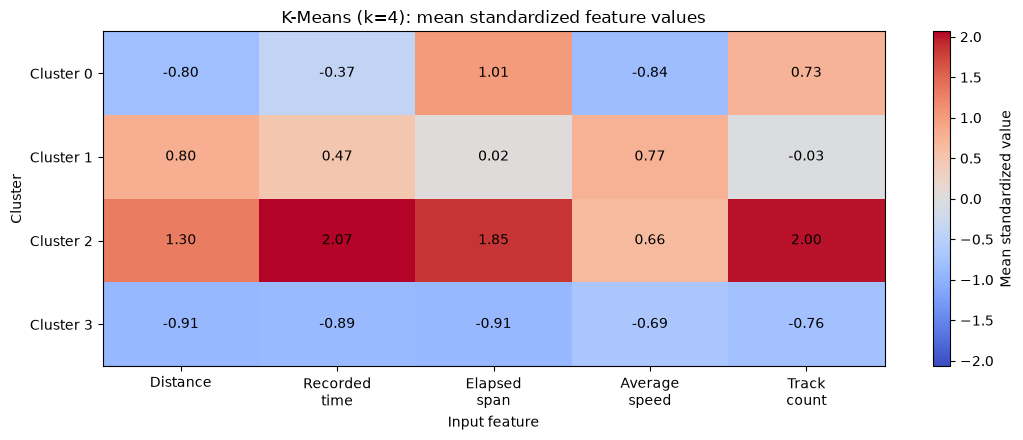

In [29]:
import matplotlib.pyplot as plt

scaled_feature_cols = [
    "scaled_total_distance_km",
    "scaled_recorded_track_hours",
    "scaled_elapsed_span_hours",
    "scaled_distance_based_avg_speed_kmh",
    "scaled_track_count",
]

cluster_feature_means = (
    features_df[scaled_feature_cols]
    .assign(kmeans_cluster=baseline_kmeans_labels_for_ari)
    .groupby("kmeans_cluster")[scaled_feature_cols]
    .mean()
    .sort_index()
)

plot_values = cluster_feature_means.to_numpy()
color_limit = max(abs(plot_values).max(), 1)

fig, ax = plt.subplots(figsize=(11, 4.5))
image = ax.imshow(
    plot_values,
    cmap="coolwarm",
    vmin=-color_limit,
    vmax=color_limit,
    aspect="auto"
)

ax.set_xticks(range(len(scaled_feature_cols)))
ax.set_xticklabels(
    [
        "Distance",
        "Recorded\ntime",
        "Elapsed\nspan",
        "Average\nspeed",
        "Track\ncount"
    ]
)
ax.set_yticks(range(len(cluster_feature_means)))
ax.set_yticklabels([f"Cluster {cluster_id}" for cluster_id in cluster_feature_means.index])
ax.set_title("K-Means (k=4): mean standardized feature values")
ax.set_xlabel("Input feature")
ax.set_ylabel("Cluster")

for row in range(plot_values.shape[0]):
    for col in range(plot_values.shape[1]):
        ax.text(
            col, row, f"{plot_values[row, col]:.2f}",
            ha="center", va="center", color="black"
        )

fig.colorbar(image, ax=ax, label="Mean standardized value")
plt.tight_layout()
plt.show()

### Prepare the final K-Means tour labels

Add the selected K-Means cluster and its provisional descriptive name to each tour record. Preview the labels and cluster counts before saving or committing the output.

In [30]:
cluster_name_map = {
    0: "Short-distance, extended-span",
    1: "Medium-distance, faster",
    2: "Long-distance, high-activity",
    3: "Very short, brief",
}

kmeans_assignments = features_df[["vehicle_id", "tour_id"]].copy()
kmeans_assignments["kmeans_cluster"] = baseline_kmeans_labels_for_ari
kmeans_assignments["cluster_name"] = kmeans_assignments["kmeans_cluster"].map(
    cluster_name_map
)

final_tour_clusters = assignments_df.merge(
    kmeans_assignments,
    on=["vehicle_id", "tour_id"],
    how="left",
    validate="one_to_one"
)

print("Tours without a K-Means label:", final_tour_clusters["kmeans_cluster"].isna().sum())
print("\nCluster counts and names:")
display(
    final_tour_clusters
    .groupby(["kmeans_cluster", "cluster_name"])
    .size()
    .rename("tour_count")
    .reset_index()
)

print("\nPreview:")
display(final_tour_clusters[
    [
        "vehicle_id",
        "tour_id",
        "kmeans_cluster",
        "cluster_name",
        "total_distance_km",
        "recorded_track_hours",
        "elapsed_span_hours",
        "long_haul",
        "requires_quality_review",
    ]
].head(10))

Tours without a K-Means label: 0

Cluster counts and names:


,kmeans_cluster,cluster_name,tour_count
0,0,"Short-distance, extended-span",2033
1,1,"Medium-distance, faster",5478
2,2,"Long-distance, high-activity",1157
3,3,"Very short, brief",4745



Preview:


,vehicle_id,tour_id,kmeans_cluster,cluster_name,total_distance_km,recorded_track_hours,elapsed_span_hours,long_haul,requires_quality_review
0,1,0,1,"Medium-distance, faster",57.945,2.059154,3.082557,False,False
1,1,1,0,"Short-distance, extended-span",0.371,0.212024,65.780914,False,False
2,1,2,0,"Short-distance, extended-span",36.554,1.324338,29.343372,False,False
3,1,3,2,"Long-distance, high-activity",6.757,4.985505,549.004571,False,False
4,1,4,2,"Long-distance, high-activity",1291.041,20.595327,45.658977,False,False
5,1,5,2,"Long-distance, high-activity",36.677,7.572085,45.919269,False,False
6,1,6,1,"Medium-distance, faster",64.381,2.680381,5.244135,False,False
7,1,7,3,"Very short, brief",0.111,0.054606,0.054606,False,False
8,1,8,2,"Long-distance, high-activity",959.976,18.086623,48.665134,False,False
9,1,9,3,"Very short, brief",0.309,0.370888,0.370888,False,False


In [31]:
preview_columns = [
    "vehicle_id",
    "tour_id",
    "kmeans_cluster",
    "cluster_name",
    "total_distance_km",
    "recorded_track_hours",
    "elapsed_span_hours",
    "long_haul",
    "requires_quality_review",
]

assert final_tour_clusters["kmeans_cluster"].notna().all()
assert final_tour_clusters["cluster_name"].eq(
    final_tour_clusters["kmeans_cluster"].map(cluster_name_map)
).all()

print(final_tour_clusters[preview_columns].head(10).to_string(index=False))

 vehicle_id  tour_id  kmeans_cluster                  cluster_name  total_distance_km  recorded_track_hours  elapsed_span_hours  long_haul  requires_quality_review
          1        0               1       Medium-distance, faster             57.945              2.059154            3.082557      False                    False
          1        1               0 Short-distance, extended-span              0.371              0.212024           65.780914      False                    False
          1        2               0 Short-distance, extended-span             36.554              1.324338           29.343372      False                    False
          1        3               2  Long-distance, high-activity              6.757              4.985505          549.004571      False                    False
          1        4               2  Long-distance, high-activity           1291.041             20.595327           45.658977      False                    False
          1     

### Review extreme elapsed spans in cluster 2

Show the tours with the longest elapsed spans, including existing quality flags and the ratio of elapsed to recorded time. This helps check for unusual tours that weren’t already flagged.

In [32]:
cluster2_extremes = final_tour_clusters.loc[
    final_tour_clusters["kmeans_cluster"] == 2
].copy()

cluster2_extremes["elapsed_to_recorded_ratio"] = (
    cluster2_extremes["elapsed_span_hours"]
    / cluster2_extremes["recorded_track_hours"].replace(0, np.nan)
)

audit_columns = [
    "vehicle_id",
    "tour_id",
    "total_distance_km",
    "recorded_track_hours",
    "elapsed_span_hours",
    "elapsed_to_recorded_ratio",
    "distance_based_avg_speed_kmh",
    "track_count",
    "long_haul",
    "requires_quality_review",
    "duration_incomplete",
    "duration_unusable",
    "negative_elapsed_span",
    "non_positive_distance",
]

display(
    cluster2_extremes
    .sort_values("elapsed_span_hours", ascending=False)[audit_columns]
    .head(10)
    .round(2)
)

,vehicle_id,tour_id,total_distance_km,recorded_track_hours,elapsed_span_hours,elapsed_to_recorded_ratio,distance_based_avg_speed_kmh,track_count,long_haul,requires_quality_review,duration_incomplete,duration_unusable,negative_elapsed_span,non_positive_distance
13407,162,13436,7714.37,174.84,4024.94,23.02,44.12,246,False,False,False,False,False,False
13352,152,13381,1121.18,28.40,3807.52,134.08,39.48,55,False,False,False,False,False,False
12855,81,12876,6118.39,113.43,3313.53,29.21,53.94,133,False,False,False,False,False,False
13408,163,13437,3175.20,66.61,3308.47,49.67,47.67,98,False,False,False,False,False,False
12960,103,12983,5059.36,110.05,3192.27,29.01,45.97,170,False,False,False,False,False,False
12837,69,12855,6029.90,139.25,3192.08,22.92,43.30,257,False,True,True,False,False,False
12911,98,12934,531.28,18.26,3098.49,169.72,29.10,52,False,True,True,False,False,False
12958,102,12981,1728.77,34.47,2967.99,86.09,50.15,93,False,False,False,False,False,False
13150,133,13177,1337.17,37.18,2854.03,76.77,35.97,132,False,False,False,False,False,False
13157,137,13184,1795.26,29.24,2850.51,97.47,61.39,28,False,False,False,False,False,False


In [33]:
time_audit = (
    cluster2_extremes
    .sort_values("elapsed_span_hours", ascending=False)
    .head(10)
    .copy()
)

parsed_start = pd.to_datetime(time_audit["start_time"], errors="coerce", utc=True)
parsed_end = pd.to_datetime(time_audit["end_time"], errors="coerce", utc=True)

time_audit["start_to_end_hours_check"] = (
    parsed_end - parsed_start
).dt.total_seconds() / 3600

time_columns = [
    "vehicle_id",
    "tour_id",
    "start_time",
    "last_track_start",
    "end_time",
    "elapsed_span_hours",
    "start_to_end_hours_check",
    "recorded_track_hours",
    "elapsed_to_recorded_ratio",
    "requires_quality_review",
]

print(time_audit[time_columns].to_string(index=False))

 vehicle_id  tour_id                       start_time                 last_track_start                         end_time  elapsed_span_hours  start_to_end_hours_check  recorded_track_hours  elapsed_to_recorded_ratio  requires_quality_review
        162    13436 2023-06-02 14:39:22.866000+00:00 2023-11-17 05:59:55.432000+00:00 2023-11-17 07:35:34.661000+00:00         4024.936610               4024.936610            174.842559                  23.020348                    False
        152    13381 2023-06-02 15:56:06.864000+00:00 2023-11-08 07:18:59.840000+00:00 2023-11-08 07:27:34.858000+00:00         3807.524443               3807.524443             28.396818                 134.082785                    False
         81    12876 2023-06-23 14:35:05.523000+00:00 2023-11-08 14:34:21.009000+00:00 2023-11-08 16:06:49.557000+00:00         3313.528898               3313.528898            113.428634                  29.212455                    False
        163    13437 2023-06-02 14:52:16

### Quantify long elapsed spans

Compare elapsed-span percentiles and counts above 7 days and 30 days by cluster. These are descriptive checkpoints, not automatic quality rules.

In [34]:
elapsed_audit = final_tour_clusters.copy()

elapsed_audit["elapsed_to_recorded_ratio"] = (
    elapsed_audit["elapsed_span_hours"]
    / elapsed_audit["recorded_track_hours"].replace(0, np.nan)
)

elapsed_rows = []

for cluster_id, group in elapsed_audit.groupby("kmeans_cluster", sort=True):
    spans = group["elapsed_span_hours"]
    ratios = group["elapsed_to_recorded_ratio"]

    row = {
        "cluster": int(cluster_id),
        "tour_count": len(group),
        "elapsed_median_h": spans.median(),
        "elapsed_p95_h": spans.quantile(0.95),
        "elapsed_p99_h": spans.quantile(0.99),
        "elapsed_max_h": spans.max(),
        "ratio_p95": ratios.quantile(0.95),
        "ratio_p99": ratios.quantile(0.99),
    }

    for label, threshold_hours in [("over_7_days", 168), ("over_30_days", 720)]:
        subset = group.loc[group["elapsed_span_hours"] > threshold_hours]
        row[f"{label}_count"] = len(subset)
        row[f"{label}_review_pct"] = (
            100 * subset["requires_quality_review"].mean()
            if len(subset) else np.nan
        )

    elapsed_rows.append(row)

display(pd.DataFrame(elapsed_rows).round(2))

,cluster,tour_count,elapsed_median_h,elapsed_p95_h,elapsed_p99_h,elapsed_max_h,ratio_p95,ratio_p99,over_7_days_count,over_7_days_review_pct,over_30_days_count,over_30_days_review_pct
0,0,2033,16.24,91.01,440.13,2778.34,325.78,2477.07,47,4.26,14,0.0
1,1,5478,5.07,17.16,43.20,329.86,5.40,19.89,4,0.00,0,NaN
2,2,1157,59.21,554.58,2805.95,4024.94,31.23,143.03,178,16.29,50,14.0
3,3,4745,0.70,4.57,11.97,18.19,29.39,215.34,0,NaN,0,NaN


### Sensitivity check: remove elapsed span

Refit K-Means with the other four standardized features. Compare its labels with the five-feature model and review the internal metrics.

In [35]:
from sklearn.cluster import KMeans
from sklearn.metrics import (
    adjusted_rand_score,
    calinski_harabasz_score,
    davies_bouldin_score,
    silhouette_score,
)

# Columns: distance, recorded time, average speed, track count
X_no_elapsed = X_kmedoids[:, [0, 1, 3, 4]]

kmeans_no_elapsed_labels = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=20
).fit_predict(X_no_elapsed)

no_elapsed_metrics = {
    "model": "K-Means without elapsed span",
    "k": 4,
    "sampled_silhouette": silhouette_score(
        X_no_elapsed,
        kmeans_no_elapsed_labels,
        sample_size=3000,
        random_state=42
    ),
    "calinski_harabasz": calinski_harabasz_score(
        X_no_elapsed,
        kmeans_no_elapsed_labels
    ),
    "davies_bouldin": davies_bouldin_score(
        X_no_elapsed,
        kmeans_no_elapsed_labels
    ),
    "ARI_vs_5D_KMeans": adjusted_rand_score(
        baseline_kmeans_labels_for_ari,
        kmeans_no_elapsed_labels
    ),
}

display(pd.DataFrame([no_elapsed_metrics]).round(4))

print("Four-feature cluster sizes:")
display(
    pd.Series(kmeans_no_elapsed_labels, name="tour_count")
    .value_counts()
    .sort_index()
)

,model,k,sampled_silhouette,calinski_harabasz,davies_bouldin,ARI_vs_5D_KMeans
0,K-Means without elapsed span,4,0.4514,11115.7227,0.8489,0.655


Four-feature cluster sizes:


tour_count
0    5182
1    5681
2    1471
3    1079
Name: count, dtype: int64

Profile K-Means without elapsed span

Compare the four-feature model’s clusters using raw tour medians, long-haul proportions, and quality-review rates. Cluster numbers may differ from the five-feature model; interpret each cluster from its own profile.

In [36]:
no_elapsed_profile_data = (
    features_df[["vehicle_id", "tour_id"]].copy()
    .assign(kmeans_cluster=kmeans_no_elapsed_labels)
    .merge(
        profile_source,
        on=["vehicle_id", "tour_id"],
        how="left",
        validate="one_to_one"
    )
    .merge(
        assignments_df[["vehicle_id", "tour_id", "long_haul"]],
        on=["vehicle_id", "tour_id"],
        how="left",
        validate="one_to_one"
    )
)

no_elapsed_profile_rows = []

for cluster_id, group in no_elapsed_profile_data.groupby("kmeans_cluster", sort=True):
    no_elapsed_profile_rows.append({
        "cluster": int(cluster_id),
        "tour_count": len(group),
        "median_distance_km": group["total_distance_km"].median(),
        "median_recorded_hours": group["recorded_track_hours"].median(),
        "median_elapsed_hours": group["elapsed_span_hours"].median(),
        "median_speed_kmh": group["distance_based_avg_speed_kmh"].median(),
        "median_track_count": group["track_count"].median(),
        "long_haul_pct": 100 * group["long_haul"].mean(),
        "quality_review_pct": 100 * group["requires_quality_review"].mean(),
    })

display(pd.DataFrame(no_elapsed_profile_rows).round(2))

,cluster,tour_count,median_distance_km,median_recorded_hours,median_elapsed_hours,median_speed_kmh,median_track_count,long_haul_pct,quality_review_pct
0,0,5182,93.22,2.68,4.57,38.00,4.0,2.64,0.98
1,1,5681,0.89,0.26,0.99,4.06,2.0,0.07,0.92
2,2,1471,564.66,10.57,27.21,55.86,15.0,29.10,3.74
3,3,1079,5.13,3.08,47.73,1.62,27.0,0.00,9.82


Check four-feature K-Means stability

Refit K-Means on 80% of tours using seeds 11, 23, and 37. Compare each sampled fit with the full four-feature solution on those same tours.

In [38]:
stability_seeds = [11, 23, 37]
stability_rows_no_elapsed = []

for seed in stability_seeds:
    sample_rng = np.random.default_rng(seed)
    sample_idx = sample_rng.choice(
        len(X_no_elapsed),
        size=int(0.8 * len(X_no_elapsed)),
        replace=False
    )

    sampled_labels = KMeans(
        n_clusters=4,
        random_state=seed,
        n_init=20
    ).fit_predict(X_no_elapsed[sample_idx])

    stability_rows_no_elapsed.append({
        "model": "K-Means without elapsed span",
        "seed": seed,
        "ARI_vs_full_data_labels": adjusted_rand_score(
            kmeans_no_elapsed_labels[sample_idx],
            sampled_labels
        ),
    })

stability_no_elapsed_df = pd.DataFrame(stability_rows_no_elapsed)
display(stability_no_elapsed_df.round(4))

print("Stability summary:")
display(
    stability_no_elapsed_df
    .groupby("model")["ARI_vs_full_data_labels"]
    .agg(["mean", "std", "min", "max"])
    .round(4)
)

,model,seed,ARI_vs_full_data_labels
0,K-Means without elapsed span,11,0.7731
1,K-Means without elapsed span,23,0.9000
2,K-Means without elapsed span,37,0.9188


Stability summary:


,mean,std,min,max
model,,,,
K-Means without elapsed span,0.864,0.0793,0.7731,0.9188


### Sensitivity check: log-transform elapsed span

Replace the raw standardized elapsed-span feature with a standardized log1p version. Compare its separation scores and assignments with the original five-feature K-Means model.

In [42]:
from sklearn.preprocessing import StandardScaler

elapsed_for_transform = (
    features_df[["vehicle_id", "tour_id"]]
    .merge(
        profile_source[["vehicle_id", "tour_id", "elapsed_span_hours"]],
        on=["vehicle_id", "tour_id"],
        how="left",
        validate="one_to_one"
    )["elapsed_span_hours"]
    .to_numpy(dtype=float)
)

assert np.isfinite(elapsed_for_transform).all()

negative_elapsed_count = int((elapsed_for_transform < 0).sum())
elapsed_log = np.log1p(np.clip(elapsed_for_transform, 0, None))

X_log_elapsed = X_kmedoids.copy()
X_log_elapsed[:, 2] = StandardScaler().fit_transform(
    elapsed_log.reshape(-1, 1)
).ravel()

kmeans_log_elapsed_labels = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=20
).fit_predict(X_log_elapsed)

log_elapsed_metrics = {
    "model": "K-Means with log elapsed span",
    "k": 4,
    "sampled_silhouette": silhouette_score(
        X_log_elapsed,
        kmeans_log_elapsed_labels,
        sample_size=3000,
        random_state=42
    ),
    "calinski_harabasz": calinski_harabasz_score(
        X_log_elapsed,
        kmeans_log_elapsed_labels
    ),
    "davies_bouldin": davies_bouldin_score(
        X_log_elapsed,
        kmeans_log_elapsed_labels
    ),
    "ARI_vs_original_5D_KMeans": adjusted_rand_score(
        baseline_kmeans_labels_for_ari,
        kmeans_log_elapsed_labels
    ),
}

print("Negative elapsed spans clipped for this comparison:", negative_elapsed_count)
display(pd.DataFrame([log_elapsed_metrics]).round(4))

print("Log-elapsed cluster sizes:")
display(
    pd.Series(kmeans_log_elapsed_labels, name="tour_count")
    .value_counts()
    .sort_index()
)

AssertionError: 

In [43]:
elapsed_check = (
    features_df[["vehicle_id", "tour_id"]]
    .merge(
        profile_source[["vehicle_id", "tour_id", "elapsed_span_hours"]],
        on=["vehicle_id", "tour_id"],
        how="left",
        validate="one_to_one"
    )
)

elapsed_check["elapsed_span_hours"] = pd.to_numeric(
    elapsed_check["elapsed_span_hours"],
    errors="coerce"
)

bad_elapsed_mask = ~np.isfinite(
    elapsed_check["elapsed_span_hours"].to_numpy(dtype=float)
)

print("Non-finite elapsed-span values:", int(bad_elapsed_mask.sum()))
display(elapsed_check.loc[bad_elapsed_mask].head(20))

Non-finite elapsed-span values: 5


,vehicle_id,tour_id,elapsed_span_hours
261,2,261,NaN
388,3,387,NaN
10437,58,10450,NaN
12698,64,12716,NaN
12976,109,13000,NaN


In [44]:
bad_keys = elapsed_check.loc[
    bad_elapsed_mask,
    ["vehicle_id", "tour_id"]
]

bad_tour_details = (
    bad_keys
    .merge(
        assignments_df[
            [
                "vehicle_id", "tour_id",
                "start_time", "last_track_start", "end_time",
                "elapsed_span_hours",
                "duration_incomplete", "duration_unusable",
                "requires_quality_review",
            ]
        ],
        on=["vehicle_id", "tour_id"],
        how="left",
        validate="one_to_one"
    )
    .merge(
        features_df[
            ["vehicle_id", "tour_id", "scaled_elapsed_span_hours"]
        ],
        on=["vehicle_id", "tour_id"],
        how="left",
        validate="one_to_one"
    )
)

display(bad_tour_details)

,vehicle_id,tour_id,start_time,last_track_start,end_time,elapsed_span_hours,duration_incomplete,duration_unusable,requires_quality_review,scaled_elapsed_span_hours
0,2,261,2022-01-03 17:57:16.407000+00:00,2022-01-03 17:57:16.407000+00:00,NaN,NaN,True,True,True,-0.112925
1,3,387,NaN,NaN,2021-10-20 13:26:58.922000+00:00,NaN,True,True,True,-0.112925
2,58,10450,2022-05-30 02:36:01.567000+00:00,2022-05-30 02:36:01.567000+00:00,NaN,NaN,True,True,True,-0.112925
3,64,12716,NaN,NaN,2022-01-21 15:42:53.166000+00:00,NaN,True,True,True,-0.112925
4,109,13000,2023-11-24 13:36:13.585000+00:00,2023-11-24 13:36:13.585000+00:00,2023-11-23 07:33:41.416000+00:00,NaN,True,True,True,-0.112925


In [45]:
from sklearn.preprocessing import StandardScaler

elapsed_for_transform = (
    features_df[["vehicle_id", "tour_id"]]
    .merge(
        profile_source[["vehicle_id", "tour_id", "elapsed_span_hours"]],
        on=["vehicle_id", "tour_id"],
        how="left",
        validate="one_to_one"
    )["elapsed_span_hours"]
    .to_numpy(dtype=float)
)

finite_elapsed = np.isfinite(elapsed_for_transform)
assert finite_elapsed.any(), "No finite elapsed-span values found."

elapsed_median = np.median(elapsed_for_transform[finite_elapsed])
missing_elapsed_count = int((~finite_elapsed).sum())

elapsed_imputed = elapsed_for_transform.copy()
elapsed_imputed[~finite_elapsed] = elapsed_median

negative_elapsed_count = int((elapsed_imputed < 0).sum())
elapsed_nonnegative = np.clip(elapsed_imputed, 0, None)
elapsed_log = np.log1p(elapsed_nonnegative)

X_log_elapsed = X_kmedoids.copy()
X_log_elapsed[:, 2] = StandardScaler().fit_transform(
    elapsed_log.reshape(-1, 1)
).ravel()

kmeans_log_elapsed_labels = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=20
).fit_predict(X_log_elapsed)

log_elapsed_metrics = {
    "model": "K-Means with log elapsed span",
    "k": 4,
    "sampled_silhouette": silhouette_score(
        X_log_elapsed,
        kmeans_log_elapsed_labels,
        sample_size=3000,
        random_state=42
    ),
    "calinski_harabasz": calinski_harabasz_score(
        X_log_elapsed,
        kmeans_log_elapsed_labels
    ),
    "davies_bouldin": davies_bouldin_score(
        X_log_elapsed,
        kmeans_log_elapsed_labels
    ),
    "ARI_vs_original_5D_KMeans": adjusted_rand_score(
        baseline_kmeans_labels_for_ari,
        kmeans_log_elapsed_labels
    ),
}

print("Missing elapsed spans median-imputed:", missing_elapsed_count)
print("Negative elapsed spans clipped to zero:", negative_elapsed_count)
display(pd.DataFrame([log_elapsed_metrics]).round(4))

print("Log-elapsed cluster sizes:")
display(
    pd.Series(kmeans_log_elapsed_labels, name="tour_count")
    .value_counts()
    .sort_index()
)

Missing elapsed spans median-imputed: 5
Negative elapsed spans clipped to zero: 0


,model,k,sampled_silhouette,calinski_harabasz,davies_bouldin,ARI_vs_original_5D_KMeans
0,K-Means with log elapsed span,4,0.4421,10270.2115,0.8545,1.0


Log-elapsed cluster sizes:


tour_count
0    2033
1    5478
2    1157
3    4745
Name: count, dtype: int64

In [46]:
print(
    "Maximum absolute change in elapsed feature:",
    float(np.max(np.abs(X_log_elapsed[:, 2] - X_kmedoids[:, 2])))
)
print(
    "Correlation between original and transformed elapsed feature:",
    float(np.corrcoef(X_kmedoids[:, 2], X_log_elapsed[:, 2])[0, 1])
)
print(
    "ARI between original and log-elapsed labels:",
    adjusted_rand_score(
        baseline_kmeans_labels_for_ari,
        kmeans_log_elapsed_labels
    )
)

metric_rows = []

for model_name, X_eval, labels in [
    ("Original 5-feature K-Means", X_kmedoids, baseline_kmeans_labels_for_ari),
    ("Log-elapsed K-Means", X_log_elapsed, kmeans_log_elapsed_labels),
]:
    metric_rows.append({
        "model": model_name,
        "sampled_silhouette": silhouette_score(
            X_eval, labels, sample_size=3000, random_state=42
        ),
        "calinski_harabasz": calinski_harabasz_score(X_eval, labels),
        "davies_bouldin": davies_bouldin_score(X_eval, labels),
    })

display(pd.DataFrame(metric_rows).round(8))

Maximum absolute change in elapsed feature: 3.725290298461914e-09
Correlation between original and transformed elapsed feature: 0.9999999999999998
ARI between original and log-elapsed labels: 1.0


,model,sampled_silhouette,calinski_harabasz,davies_bouldin
0,Original 5-feature K-Means,0.442142,10270.211538,0.854493
1,Log-elapsed K-Means,0.442142,10270.211538,0.854493


In [47]:
from sklearn.cluster import KMeans
from sklearn.metrics import (
    calinski_harabasz_score,
    davies_bouldin_score,
    silhouette_score,
)

rng = np.random.default_rng(42)
silhouette_sample_idx = rng.choice(
    len(X_kmedoids),
    size=min(3000, len(X_kmedoids)),
    replace=False
)

k_sweep_rows = []

for k in range(2, 9):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )
    labels = model.fit_predict(X_kmedoids)
    cluster_sizes = np.bincount(labels)

    k_sweep_rows.append({
        "k": k,
        "sampled_silhouette": silhouette_score(
            X_kmedoids[silhouette_sample_idx],
            labels[silhouette_sample_idx]
        ),
        "calinski_harabasz": calinski_harabasz_score(
            X_kmedoids,
            labels
        ),
        "davies_bouldin": davies_bouldin_score(
            X_kmedoids,
            labels
        ),
        "inertia": model.inertia_,
        "smallest_cluster": int(cluster_sizes.min()),
        "largest_cluster": int(cluster_sizes.max()),
    })

k_sweep_df = pd.DataFrame(k_sweep_rows)
display(k_sweep_df.round(4))

,k,sampled_silhouette,calinski_harabasz,davies_bouldin,inertia,smallest_cluster,largest_cluster
0,2,0.4235,10909.9891,0.9529,36980.7656,6542,6871
1,3,0.4382,10122.9249,1.0017,26721.7188,1638,6284
2,4,0.4525,10270.2115,0.8545,20336.5527,1157,5478
3,5,0.3948,9879.3979,0.9455,16990.0547,981,4114
4,6,0.4036,9733.8253,0.9049,14484.4854,672,3870
5,7,0.3983,9247.3225,0.9319,13050.9434,578,3770
6,8,0.3988,8910.4725,0.8666,11863.6797,4,3762


In [48]:
elapsed_check = (
    features_df[["vehicle_id", "tour_id"]]
    .merge(
        profile_source[["vehicle_id", "tour_id", "elapsed_span_hours"]],
        on=["vehicle_id", "tour_id"],
        how="left",
        validate="one_to_one"
    )
)

elapsed_check["elapsed_span_hours"] = pd.to_numeric(
    elapsed_check["elapsed_span_hours"],
    errors="coerce"
)

bad_elapsed_mask = ~np.isfinite(
    elapsed_check["elapsed_span_hours"].to_numpy(dtype=float)
)

print("Non-finite elapsed-span values:", int(bad_elapsed_mask.sum()))
display(elapsed_check.loc[bad_elapsed_mask].head(20))

Non-finite elapsed-span values: 5


,vehicle_id,tour_id,elapsed_span_hours
261,2,261,NaN
388,3,387,NaN
10437,58,10450,NaN
12698,64,12716,NaN
12976,109,13000,NaN
